In [69]:
from pymatgen.core import Structure
import numpy as np
import pandas as pd

In [70]:
cif_path = "/Users/andrewweiland/Andrews_Lab_Research/electride-ml-predictor/A2BC2/structures/elfcar/Ca2YP2.cif"

structure = Structure.from_file(cif_path)

print(structure)
print()
print("Number of sites in unit cell:", len(structure))
print("Formula:", structure.composition.reduced_formula)

Full Formula (Ca4 Y2 P4)
Reduced Formula: Ca2YP2
abc   :   7.738360   7.738360   4.018232
angles:  90.000000  90.000000  90.000000
pbc   :       True       True       True
Sites (10)
  #  SP           a         b    c
---  ----  --------  --------  ---
  0  Ca    0.858131  0.358131  0.5
  1  Ca    0.641869  0.858131  0.5
  2  Ca    0.358131  0.141869  0.5
  3  Ca    0.141869  0.641869  0.5
  4  Y     0         0         0
  5  Y     0.5       0.5       0
  6  P     0.168005  0.331995  0
  7  P     0.831995  0.668005  0
  8  P     0.668005  0.168005  0
  9  P     0.331995  0.831995  0

Number of sites in unit cell: 10
Formula: Ca2YP2


In [71]:
print("Lattice matrix, Angstrom:")
print(structure.lattice.matrix)

print()
print("a, b, c:", structure.lattice.abc)
print("alpha, beta, gamma:", structure.lattice.angles)
print("Volume:", structure.volume)

Lattice matrix, Angstrom:
[[ 7.7383600e+00  0.0000000e+00  4.7383789e-16]
 [-4.7383789e-16  7.7383600e+00  4.7383789e-16]
 [ 0.0000000e+00  0.0000000e+00  4.0182320e+00]]

a, b, c: (7.73836, 7.73836, 4.018232)
alpha, beta, gamma: (90.0, 90.0, 90.0)
Volume: 240.6206345112064


In [72]:
site_rows = []

for i, site in enumerate(structure):
    site_rows.append({
        "site_index": i,
        "element": site.species_string,
        "frac_x": site.frac_coords[0],
        "frac_y": site.frac_coords[1],
        "frac_z": site.frac_coords[2],
        "cart_x": site.coords[0],
        "cart_y": site.coords[1],
        "cart_z": site.coords[2],
    })

sites_df = pd.DataFrame(site_rows)
sites_df

,site_index,element,frac_x,frac_y,frac_z,cart_x,cart_y,cart_z
0,0,Ca,0.858131,0.358131,0.5,6.640527,2.771347,2.009116e+00
1,1,Ca,0.641869,0.858131,0.5,4.967013,6.640527,2.009116e+00
2,2,Ca,0.358131,0.141869,0.5,2.771347,1.097833,2.009116e+00
3,3,Ca,0.141869,0.641869,0.5,1.097833,4.967013,2.009116e+00
4,4,Y,0.000000,0.000000,0.0,0.000000,0.000000,0.000000e+00
5,5,Y,0.500000,0.500000,0.0,3.869180,3.869180,4.738379e-16
6,6,P,0.168005,0.331995,0.0,1.300083,2.569097,2.369189e-16
7,7,P,0.831995,0.668005,0.0,6.438277,5.169263,7.107568e-16
8,8,P,0.668005,0.168005,0.0,5.169263,1.300083,3.961332e-16
9,9,P,0.331995,0.831995,0.0,2.569097,6.438277,5.515426e-16


In [73]:
cutoff = 6.0  # Angstrom

neighbors = structure.get_all_neighbors(r=cutoff)

print("Number of atoms:", len(neighbors))
print("Neighbor counts per atom:")

for i, neighs in enumerate(neighbors):
    print(
        i,
        structure[i].species_string,
        "has",
        len(neighs),
        "neighbors within",
        cutoff,
        "Angstrom"
    )

Number of atoms: 10
Neighbor counts per atom:
0 Ca has 43 neighbors within 6.0 Angstrom
1 Ca has 43 neighbors within 6.0 Angstrom
2 Ca has 43 neighbors within 6.0 Angstrom
3 Ca has 43 neighbors within 6.0 Angstrom
4 Y has 38 neighbors within 6.0 Angstrom
5 Y has 38 neighbors within 6.0 Angstrom
6 P has 43 neighbors within 6.0 Angstrom
7 P has 43 neighbors within 6.0 Angstrom
8 P has 43 neighbors within 6.0 Angstrom
9 P has 43 neighbors within 6.0 Angstrom


In [74]:
center_atom = 0

print("Center atom:")
print(center_atom, structure[center_atom])
print()

for n in neighbors[center_atom][:10]:
    print("neighbor index:", n.index)
    print("neighbor element:", n.species_string)
    print("distance:", round(n.nn_distance, 4))
    print("periodic image:", n.image)
    print("neighbor frac coords:", n.frac_coords)
    print("---")

Center atom:
0 [6.64052661 2.77134661 2.009116  ] Ca

neighbor index: 1
neighbor element: Ca
distance: 5.8239
periodic image: (np.float64(0.0), np.float64(-1.0), np.float64(-1.0))
neighbor frac coords: [ 0.641869 -0.141869 -0.5     ]
---
neighbor index: 1
neighbor element: Ca
distance: 4.2156
periodic image: (np.float64(0.0), np.float64(-1.0), np.float64(0.0))
neighbor frac coords: [ 0.641869 -0.141869  0.5     ]
---
neighbor index: 1
neighbor element: Ca
distance: 5.8239
periodic image: (np.float64(0.0), np.float64(-1.0), np.float64(1.0))
neighbor frac coords: [ 0.641869 -0.141869  1.5     ]
---
neighbor index: 2
neighbor element: Ca
distance: 5.8239
periodic image: (np.float64(0.0), np.float64(0.0), np.float64(-1.0))
neighbor frac coords: [ 0.358131  0.141869 -0.5     ]
---
neighbor index: 6
neighbor element: P
distance: 5.7094
periodic image: (np.float64(0.0), np.float64(0.0), np.float64(1.0))
neighbor frac coords: [0.168005 0.331995 1.      ]
---
neighbor index: 8
neighbor element:

In [75]:
edge_rows = []

for i, neighs in enumerate(neighbors):
    for n in neighs:
        j = n.index
        
        edge_rows.append({
            "source": i,
            "target": j,
            "source_element": structure[i].species_string,
            "target_element": structure[j].species_string,
            "distance": n.nn_distance,
            "image_x": n.image[0],
            "image_y": n.image[1],
            "image_z": n.image[2],
        })

edges_df = pd.DataFrame(edge_rows)

print("Number of directed edges:", len(edges_df))
edges_df.head()

Number of directed edges: 420


,source,target,source_element,target_element,distance,image_x,image_y,image_z
0,0,1,Ca,Ca,5.823864,0.0,-1.0,-1.0
1,0,1,Ca,Ca,4.215590,0.0,-1.0,0.0
2,0,1,Ca,Ca,5.823864,0.0,-1.0,1.0
3,0,2,Ca,Ca,5.823864,0.0,0.0,-1.0
4,0,6,Ca,P,5.709447,0.0,0.0,1.0


In [76]:
boundary_edges = edges_df[
    (edges_df["image_x"] != 0) |
    (edges_df["image_y"] != 0) |
    (edges_df["image_z"] != 0)
]

print("Number of periodic boundary-crossing edges:", len(boundary_edges))
boundary_edges.head(20)

Number of periodic boundary-crossing edges: 338


,source,target,source_element,target_element,distance,image_x,image_y,image_z
0,0,1,Ca,Ca,5.823864,0.0,-1.0,-1.0
1,0,1,Ca,Ca,4.215590,0.0,-1.0,0.0
2,0,1,Ca,Ca,5.823864,0.0,-1.0,1.0
3,0,2,Ca,Ca,5.823864,0.0,0.0,-1.0
4,0,6,Ca,P,5.709447,0.0,0.0,1.0
5,0,8,Ca,P,2.892366,0.0,0.0,1.0
7,0,5,Ca,Y,3.594739,0.0,0.0,1.0
12,0,2,Ca,Ca,5.823864,0.0,0.0,1.0
13,0,1,Ca,Ca,5.823864,0.0,0.0,-1.0
14,0,9,Ca,P,5.836049,0.0,0.0,1.0


In [77]:
node_features = []

for site in structure:
    element = site.specie
    node_features.append([
        element.Z,
        element.X if element.X is not None else 0.0,
        element.atomic_radius if element.atomic_radius is not None else 0.0,
    ])

node_features = np.array(node_features, dtype=float)

print("Node feature matrix shape:", node_features.shape)
print("Columns: atomic_number, electronegativity, atomic_radius")
print(node_features)

Node feature matrix shape: (10, 3)
Columns: atomic_number, electronegativity, atomic_radius
[[20.    1.    1.8 ]
 [20.    1.    1.8 ]
 [20.    1.    1.8 ]
 [20.    1.    1.8 ]
 [39.    1.22  1.8 ]
 [39.    1.22  1.8 ]
 [15.    2.19  1.  ]
 [15.    2.19  1.  ]
 [15.    2.19  1.  ]
 [15.    2.19  1.  ]]


In [78]:
edge_index = edges_df[["source", "target"]].to_numpy().T
edge_distances = edges_df["distance"].to_numpy().reshape(-1, 1)
edge_images = edges_df[["image_x", "image_y", "image_z"]].to_numpy()

print("edge_index shape:", edge_index.shape)
print("edge_distances shape:", edge_distances.shape)
print("edge_images shape:", edge_images.shape)

print()
print("First 10 edges:")
for k in range(10):
    print(
        "edge",
        k,
        ":",
        edge_index[0, k],
        "->",
        edge_index[1, k],
        "distance =",
        round(edge_distances[k, 0], 4),
        "image =",
        edge_images[k]
    )

edge_index shape: (2, 420)
edge_distances shape: (420, 1)
edge_images shape: (420, 3)

First 10 edges:
edge 0 : 0 -> 1 distance = 5.8239 image = [ 0. -1. -1.]
edge 1 : 0 -> 1 distance = 4.2156 image = [ 0. -1.  0.]
edge 2 : 0 -> 1 distance = 5.8239 image = [ 0. -1.  1.]
edge 3 : 0 -> 2 distance = 5.8239 image = [ 0.  0. -1.]
edge 4 : 0 -> 6 distance = 5.7094 image = [0. 0. 1.]
edge 5 : 0 -> 8 distance = 2.8924 image = [0. 0. 1.]
edge 6 : 0 -> 6 distance = 5.7094 image = [0. 0. 0.]
edge 7 : 0 -> 5 distance = 3.5947 image = [0. 0. 1.]
edge 8 : 0 -> 3 distance = 5.9617 image = [0. 0. 0.]
edge 9 : 0 -> 2 distance = 4.2156 image = [0. 0. 0.]


In [79]:
def gaussian_distance_expansion(distances, centers, width):
    return np.exp(-((distances - centers) ** 2) / width**2)

centers = np.linspace(0, cutoff, 40)
width = centers[1] - centers[0]

edge_distance_features = gaussian_distance_expansion(edge_distances, centers, width)

print("Expanded edge feature shape:", edge_distance_features.shape)
print("Number of distance basis functions:", len(centers))

print()
print("Raw distance:", edge_distances[0, 0])
print("Expanded vector for first edge:")
print(edge_distance_features[0])

Expanded edge feature shape: (420, 40)
Number of distance basis functions: 40

Raw distance: 5.823863729805114
Expanded vector for first edge:
[0.00000000e+000 0.00000000e+000 0.00000000e+000 0.00000000e+000
 0.00000000e+000 0.00000000e+000 0.00000000e+000 0.00000000e+000
 0.00000000e+000 0.00000000e+000 0.00000000e+000 6.13836338e-314
 4.78425111e-291 5.04645465e-269 7.20393555e-248 1.39175984e-227
 3.63889745e-208 1.28761601e-189 6.16614819e-172 3.99624939e-155
 3.50511479e-139 4.16066685e-124 6.68397284e-110 1.45317342e-096
 4.27573965e-084 1.70261359e-072 9.17554721e-062 6.69204556e-052
 6.60536529e-043 8.82360031e-035 1.59516588e-027 3.90280552e-021
 1.29228709e-015 5.79098098e-011 3.51201455e-007 2.88251457e-004
 3.20182618e-002 4.81321242e-001 9.79226914e-001 2.69614156e-001]


In [80]:
graph = {
    "formula": structure.composition.reduced_formula,
    "num_nodes": len(structure),
    "lattice": structure.lattice.matrix,
    "frac_coords": structure.frac_coords,
    "cart_coords": structure.cart_coords,
    "node_features": node_features,
    "edge_index": edge_index,
    "edge_distances": edge_distances,
    "edge_distance_features": edge_distance_features,
    "edge_images": edge_images,
}

for key, value in graph.items():
    if hasattr(value, "shape"):
        print(key, value.shape)
    else:
        print(key, value)

formula Ca2YP2
num_nodes 10
lattice (3, 3)
frac_coords (10, 3)
cart_coords (10, 3)
node_features (10, 3)
edge_index (2, 420)
edge_distances (420, 1)
edge_distance_features (420, 40)
edge_images (420, 3)


# ELFmax graph neural network

This section loads the preprocessed A2BC2 graphs, matches them to `labels.csv`, trains a small message-passing model, and evaluates its ELFmax predictions.

In [81]:
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from torch import nn
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader
from torch_geometric.nn import GINEConv

SEED = 42
TEST_SIZE = 0.20
HIDDEN_DIM = 64
NUM_LAYERS = 3
LEARNING_RATE = 0.001
WEIGHT_DECAY = 1e-4
EPOCHS = 300
BATCH_SIZE = 16

BASE_DIR = Path.cwd()
if BASE_DIR.name != "A2BC2":
    BASE_DIR = BASE_DIR / "A2BC2"
GRAPH_PATH = BASE_DIR / "processed" / "graphs.pt"
LABEL_PATH = BASE_DIR / "labels.csv"
MODEL_PATH = BASE_DIR / "elfmax_gnn.pt"
DEVICE = torch.device("mps" if torch.backends.mps.is_available() else "cpu")

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
print("Device:", DEVICE)

Device: mps


## Data processing

In [82]:
labels = pd.read_csv(LABEL_PATH)
graphs = torch.load(GRAPH_PATH, weights_only=False)

assert len(graphs) == len(labels), (len(graphs), len(labels))
assert labels["cif_filename"].notna().all()
assert labels["cif_filename"].is_unique

# preprocess_graphs.py saved graphs in the same order as labels.csv.
# Keep the filename with each graph so all later matching is explicit.
dataset = []
for graph, row in zip(graphs, labels.itertuples(index=False)):
    assert (BASE_DIR / "cifs" / row.cif_filename).is_file()
    assert np.isfinite(graph["node_features"]).all()
    assert np.isfinite(graph["edge_distance_features"]).all()
    assert graph["edge_index"].shape[0] == 2

    data = Data(
        x=torch.tensor(graph["node_features"], dtype=torch.float32),
        void_x=torch.tensor(graph["void_features"], dtype=torch.float32),
        edge_index=torch.tensor(graph["edge_index"], dtype=torch.long),
        edge_attr=torch.tensor(graph["edge_distance_features"], dtype=torch.float32),
        y=torch.tensor([row.ELFmax], dtype=torch.float32),
    )
    data.ghost_mask = torch.zeros(graph["num_nodes"], dtype=torch.bool)
    data.ghost_mask[graph["ghost_index"]] = True
    data.cif_filename = row.cif_filename
    dataset.append(data)

print(f"Matched {len(dataset)} graphs to labels using cif_filename.")
print("Example:", dataset[0].cif_filename, "-> ELFmax", dataset[0].y.item())
print("Atom/ghost nodes:", dataset[0].x.shape, dataset[0].void_x.shape)
print("Edge features:", dataset[0].edge_attr.shape)

Matched 145 graphs to labels using cif_filename.
Example: Pr2YSi2.cif -> ELFmax 0.8087175488471985
Atom/ghost nodes: torch.Size([11, 18]) torch.Size([11, 4])
Edge features: torch.Size([464, 40])


## Train/test split

In [83]:
generator = torch.Generator().manual_seed(SEED)
test_count = round(TEST_SIZE * len(dataset))
train_count = len(dataset) - test_count
train_dataset, test_dataset = torch.utils.data.random_split(
    dataset, [train_count, test_count], generator=generator
)

# Standardize node features using training atoms only.
train_nodes = torch.cat([data.x[~data.ghost_mask] for data in train_dataset])
node_mean = train_nodes.mean(dim=0)
node_std = train_nodes.std(dim=0).clamp_min(1e-8)
for data in dataset:
    data.x[~data.ghost_mask] = (data.x[~data.ghost_mask] - node_mean) / node_std

# Normalize targets using training data only.
train_targets = torch.tensor([data.y.item() for data in train_dataset])
target_mean = train_targets.mean()
target_std = train_targets.std().clamp_min(1e-8)
for data in dataset:
    data.y = (data.y - target_mean) / target_std

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE)
print(f"Training structures: {len(train_dataset)}")
print(f"Test structures: {len(test_dataset)}")
print(f"Training ELFmax mean/std: {target_mean.item():.4f} / {target_std.item():.4f}")

Training structures: 116
Test structures: 29
Training ELFmax mean/std: 0.7967 / 0.0458


## Model framework

In [84]:
class ELFmaxGNN(nn.Module):
    def __init__(self, node_dim, edge_dim, hidden_dim=64, num_layers=3):
        super().__init__()
        self.atom_encoder = nn.Linear(node_dim, hidden_dim)
        self.void_encoder = nn.Linear(4, hidden_dim)
        self.layers = nn.ModuleList()
        self.norms = nn.ModuleList()
        for _ in range(num_layers):
            mlp = nn.Sequential(
                nn.Linear(hidden_dim, hidden_dim),
                nn.SiLU(),
                nn.Linear(hidden_dim, hidden_dim),
            )
            self.layers.append(GINEConv(mlp, edge_dim=edge_dim))
            self.norms.append(nn.BatchNorm1d(hidden_dim))
        self.readout = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, 1),
        )

    def forward(self, data):
        atom_x = self.atom_encoder(data.x)
        void_x = self.void_encoder(data.void_x)
        x = torch.where(data.ghost_mask.unsqueeze(-1), void_x, atom_x)
        for layer, norm in zip(self.layers, self.norms):
            updated = layer(x, data.edge_index, data.edge_attr)
            x = x + torch.relu(norm(updated))
        ghost_x = x[data.ghost_mask]
        return self.readout(ghost_x).squeeze(-1)

model = ELFmaxGNN(
    node_dim=dataset[0].num_node_features,
    edge_dim=dataset[0].num_edge_features,
    hidden_dim=HIDDEN_DIM,
    num_layers=NUM_LAYERS,
).to(DEVICE)
print(model)
print(f"Trainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

ELFmaxGNN(
  (atom_encoder): Linear(in_features=18, out_features=64, bias=True)
  (void_encoder): Linear(in_features=4, out_features=64, bias=True)
  (layers): ModuleList(
    (0-2): 3 x GINEConv(nn=Sequential(
      (0): Linear(in_features=64, out_features=64, bias=True)
      (1): SiLU()
      (2): Linear(in_features=64, out_features=64, bias=True)
    ))
  )
  (norms): ModuleList(
    (0-2): 3 x BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  )
  (readout): Sequential(
    (0): Linear(in_features=64, out_features=64, bias=True)
    (1): SiLU()
    (2): Linear(in_features=64, out_features=1, bias=True)
  )
)
Trainable parameters: 38,977


## Training

Epoch   1 | train loss 1.2520 | test loss 1.8473
Epoch  50 | train loss 0.1388 | test loss 0.3650
Epoch 100 | train loss 0.1532 | test loss 0.2147
Epoch 150 | train loss 0.0432 | test loss 0.1606
Epoch 200 | train loss 0.0351 | test loss 0.0997
Epoch 250 | train loss 0.0181 | test loss 0.1111
Epoch 300 | train loss 0.0215 | test loss 0.0920
Final test MSE in normalized units: 0.0920
Training-set performance after training:
Train MAE:  0.0032
Train RMSE: 0.0043
Train R^2:  0.9912


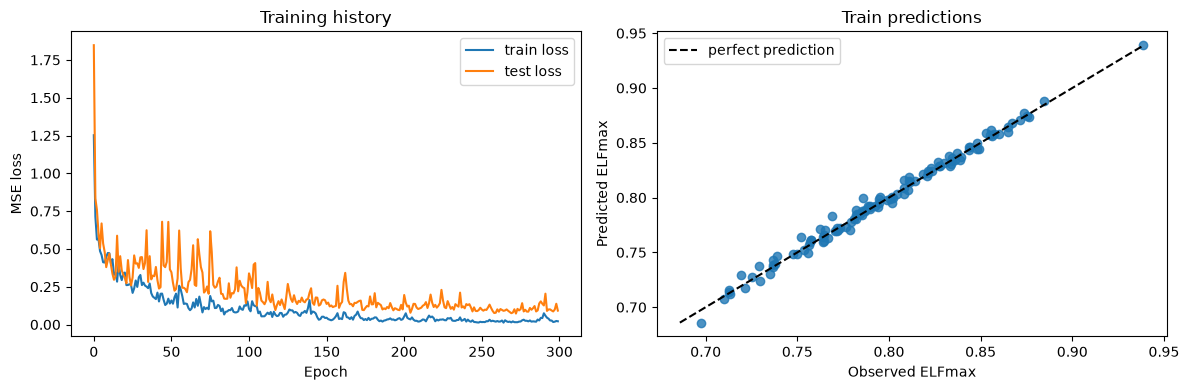

In [85]:
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
loss_function = nn.MSELoss()
history = []

for epoch in range(1, EPOCHS + 1):
    model.train()
    train_loss = 0.0
    for batch in train_loader:
        batch = batch.to(DEVICE)
        optimizer.zero_grad()
        predictions = model(batch)
        loss = loss_function(predictions, batch.y)
        loss.backward()
        optimizer.step()
        train_loss += loss.item() * batch.num_graphs
    train_loss /= len(train_dataset)

    model.eval()
    test_loss = 0.0
    with torch.no_grad():
        for batch in test_loader:
            batch = batch.to(DEVICE)
            test_loss += loss_function(model(batch), batch.y).item() * batch.num_graphs
    test_loss /= len(test_dataset)
    history.append((train_loss, test_loss))

    if epoch == 1 or epoch % 50 == 0:
        print(f"Epoch {epoch:3d} | train loss {train_loss:.4f} | test loss {test_loss:.4f}")

print(f"Final test MSE in normalized units: {test_loss:.4f}")

def predict(loader):
    model.eval()
    actual = []
    predicted = []
    with torch.no_grad():
        for batch in loader:
            batch = batch.to(DEVICE)
            predicted.extend(model(batch).cpu().numpy())
            actual.extend(batch.y.cpu().numpy())
    actual = np.asarray(actual) * target_std.item() + target_mean.item()
    predicted = np.asarray(predicted) * target_std.item() + target_mean.item()
    return actual, predicted

def print_metrics(name, actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    rmse = mean_squared_error(actual, predicted) ** 0.5
    r2 = r2_score(actual, predicted)
    print(f"{name} MAE:  {mae:.4f}")
    print(f"{name} RMSE: {rmse:.4f}")
    print(f"{name} R^2:  {r2:.4f}")

train_actual, train_predicted = predict(train_loader)
print("Training-set performance after training:")
print_metrics("Train", train_actual, train_predicted)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(np.array(history)[:, 0], label="train loss")
axes[0].plot(np.array(history)[:, 1], label="test loss")
axes[0].set(xlabel="Epoch", ylabel="MSE loss", title="Training history")
axes[0].legend()
axes[1].scatter(train_actual, train_predicted, alpha=0.8)
train_limits = [min(train_actual.min(), train_predicted.min()), max(train_actual.max(), train_predicted.max())]
axes[1].plot(train_limits, train_limits, "k--", label="perfect prediction")
axes[1].set(xlabel="Observed ELFmax", ylabel="Predicted ELFmax", title="Train predictions")
axes[1].legend()
plt.tight_layout()
plt.show()

## Evaluation

Test-set performance after evaluation:
Test MAE:  0.0090
Test RMSE: 0.0139
Test R^2:  0.8739
Mean baseline MAE: 0.0321


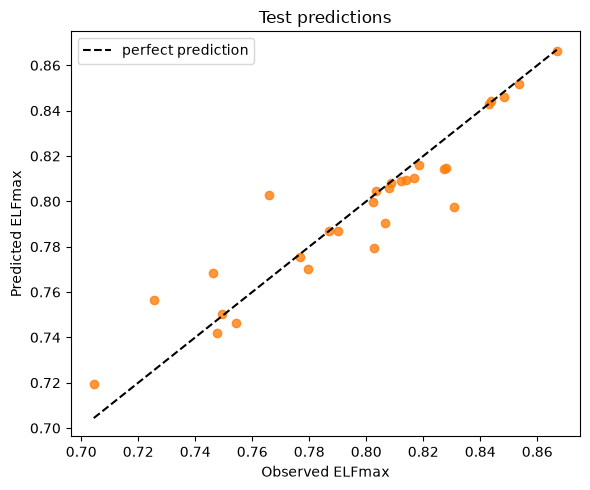

,cif_filename,observed_ELFmax,predicted_ELFmax
0,Lu2ScGa2.cif,0.754445,0.746432
1,Tm2MgGa2.cif,0.704399,0.719498
2,Sm2YbSi2.cif,0.812039,0.809084
3,Tb2ScSi2.cif,0.853492,0.851955
4,Dy2TmSi2.cif,0.776748,0.775491
5,La2LiGe2.cif,0.765830,0.802591
6,Yb2DyP2.cif,0.746235,0.768246
7,Y2ScGa2.cif,0.806545,0.790580
8,Pr2LuGe2.cif,0.843613,0.844399
9,Dy2HoSi2.cif,0.749559,0.750280


In [86]:
actual, predicted = predict(test_loader)
filenames = [data.cif_filename for data in test_dataset]

baseline = np.full_like(actual, target_mean.item())
baseline_mae = mean_absolute_error(actual, baseline)

print("Test-set performance after evaluation:")
print_metrics("Test", actual, predicted)
print(f"Mean baseline MAE: {baseline_mae:.4f}")

fig, ax = plt.subplots(figsize=(6, 5))
plot_limits = [min(actual.min(), predicted.min()), max(actual.max(), predicted.max())]
ax.scatter(actual, predicted, alpha=0.8, color="tab:orange")
ax.plot(plot_limits, plot_limits, "k--", label="perfect prediction")
ax.set(xlabel="Observed ELFmax", ylabel="Predicted ELFmax", title="Test predictions")
ax.legend()
plt.tight_layout()
plt.show()

pd.DataFrame({"cif_filename": filenames, "observed_ELFmax": actual, "predicted_ELFmax": predicted})

## Save the trained model

In [87]:
torch.save(
    {
        "model_state_dict": model.state_dict(),
        "node_dim": dataset[0].num_node_features,
        "edge_dim": dataset[0].num_edge_features,
        "hidden_dim": HIDDEN_DIM,
        "num_layers": NUM_LAYERS,
        "target_mean": target_mean.item(),
        "target_std": target_std.item(),
    },
    MODEL_PATH,
)
print(f"Saved model checkpoint to {MODEL_PATH}")

Saved model checkpoint to /Users/andrewweiland/Andrews_Lab_Research/electride-ml-predictor/A2BC2/elfmax_gnn.pt
